In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import tifffile
from skimage import filters, measure
from skimage.io import imread

In [3]:
filename = 'Img01_mRNA.tif'
img01_cells = imread(filename)

In [4]:
print(type(img01_cells))
print(img01_cells.shape)

<class 'numpy.ndarray'>
(366, 594)


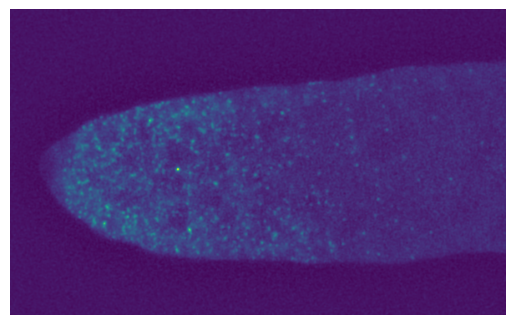

In [5]:
plt.imshow(img01_cells)
plt.axis('off')
plt.show()

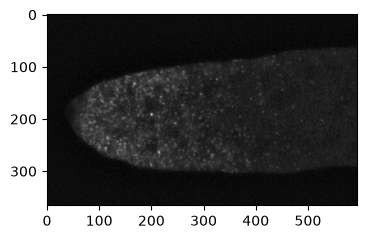

In [6]:
fh, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(img01_cells, cmap='gray')

In [7]:
img01_cells.shape

(366, 594)

In [8]:
img01_cells.flatten().shape

(217404,)

Text(0, 0.5, 'Count')

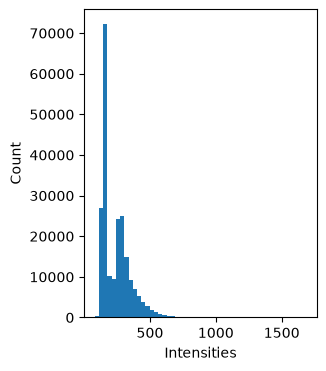

In [9]:
fh, ax = plt.subplots(1, 1, figsize=(3, 4))
ax.hist(img01_cells.flatten(), bins=50)
ax.set_xlabel('Intensities')
ax.set_ylabel('Count')

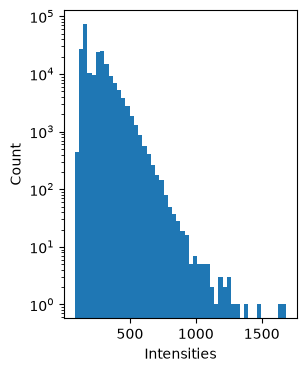

In [10]:
fh, ax = plt.subplots(1, 1, figsize=(3, 4))
ax.hist(img01_cells.flatten(), bins=50)
ax.set_xlabel('Intensities')
ax.set_ylabel('Count')
ax.set_yscale('log')

skimage.filters.thresholding.threshold_isodata
skimage.filters.thresholding.threshold_li
skimage.filters.thresholding.threshold_mean
skimage.filters.thresholding.threshold_minimum
skimage.filters.thresholding.threshold_otsu
skimage.filters.thresholding.threshold_triangle
skimage.filters.thresholding.threshold_yen
(<Figure size 800x500 with 8 Axes>, array([<Axes: title={'center': 'Original'}>,
       <Axes: title={'center': 'Isodata'}>,
       <Axes: title={'center': 'Li'}>, <Axes: title={'center': 'Mean'}>,
       <Axes: title={'center': 'Minimum'}>,
       <Axes: title={'center': 'Otsu'}>,
       <Axes: title={'center': 'Triangle'}>,
       <Axes: title={'center': 'Yen'}>], dtype=object))


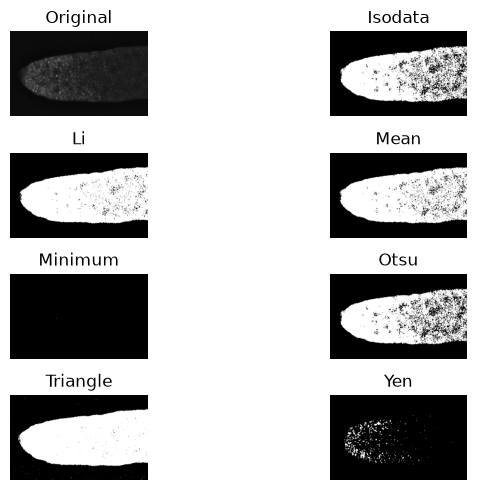

In [11]:
testing = filters.try_all_threshold(img01_cells)
print(testing)

In [12]:
thresh = filters.threshold_yen(img01_cells)
print(thresh)

513


In [13]:
img01_cells.shape

(366, 594)

In [14]:
mask = img01_cells > thresh
print(mask.shape)
print(np.unique(mask))

(366, 594)
[False  True]


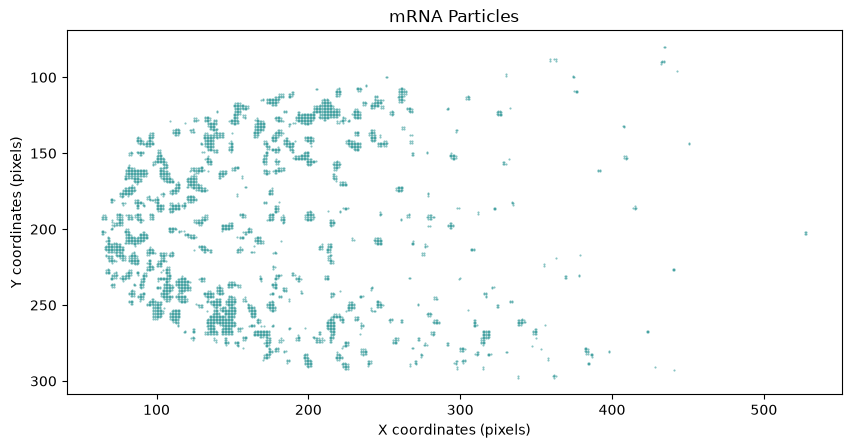

In [15]:
x, y = np.where(img01_cells >= thresh)
fh, ax = plt.subplots(1, 1, figsize=(10, 6))
plt.scatter(y, x, s=1, alpha=0.5, c='teal', marker='.')
plt.gca().set_aspect('equal', adjustable='box')
plt.title("mRNA Particles")
plt.xlabel("X coordinates (pixels)")
plt.ylabel("Y coordinates (pixels)")
plt.gca().invert_yaxis()
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_particles_scatter.png")
plt.show()

In [16]:
print(type(img01_cells))
print(img01_cells.shape)

<class 'numpy.ndarray'>
(366, 594)


In [17]:
import pandas as pd
from skimage.feature import blob_log
from skimage import img_as_float

In [18]:
img = imread(filename)
print(f"Image Data Type: {img.dtype}")
print(f"Image Max Raw Intensity: {img.max()}")

Image Data Type: uint16
Image Max Raw Intensity: 1685


In [86]:
img_float = img_as_float(img01_cells)
spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.001)
print(f"Total Unique Particles Isolated: {len(spots)}")

Total Unique Particles Isolated: 447


In [87]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


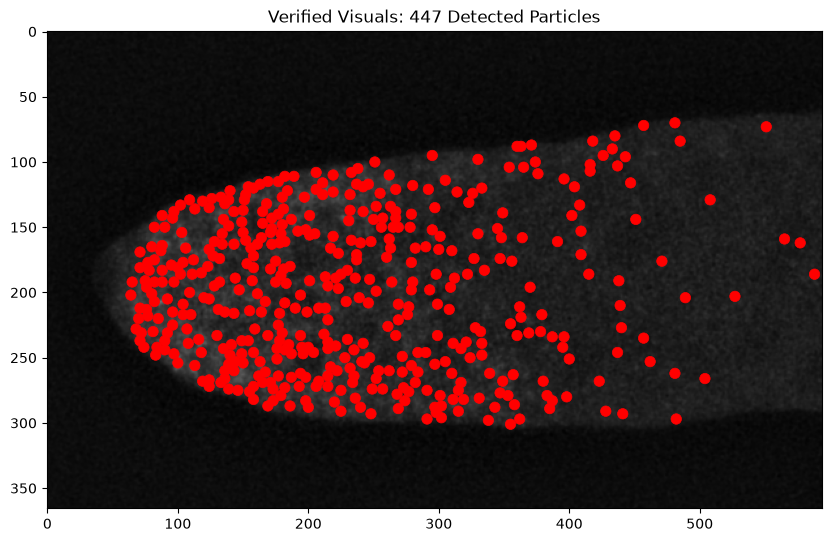

In [89]:
img_2d = img01_cells
img_display = img_2d.astype(float)
fig, ax = plt.subplots(figsize=(10, 10))
plt.imshow(img_display, cmap='gray', vmin=img_display.min(), vmax=img_display.max())
for spot in spots:
    y, x, r = spot
    circle = plt.Circle((x, y), radius=4, color='red', fill=True, linewidth=0.5)
    ax.add_patch(circle)
ax.set_title(f"Verified Visuals: {len(spots)} Detected Particles")
ax.axis('on')
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/verified_mrna_visual.png", dpi=300)
plt.show()

In [81]:
spots_df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
print(spots_df.head())

       y      x     sigma
0  191.0  201.0  1.444444
1  264.0  215.0  1.888889
2  256.0  113.0  1.666667
3  132.0  168.0  2.111111
4  248.0  140.0  1.444444


In [23]:
print(spots.shape)
print(spots[:5])

(447, 3)
[[191.         201.           1.44444444]
 [264.         215.           1.88888889]
 [256.         113.           1.66666667]
 [132.         168.           2.11111111]
 [248.         140.           1.44444444]]


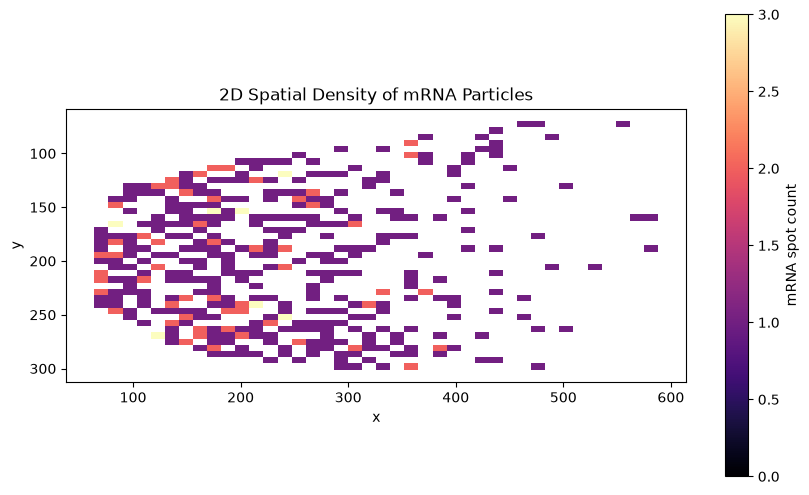

In [24]:
x, y = np.where(img01_cells >= thresh)
fh, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=spots_df, x="x", y="y", bins=40, cmap="magma", cbar=True, cbar_kws={"label": "mRNA spot count"}, ax=ax)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.title("2D Spatial Density of mRNA Particles")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_heatmap.png")
plt.show()

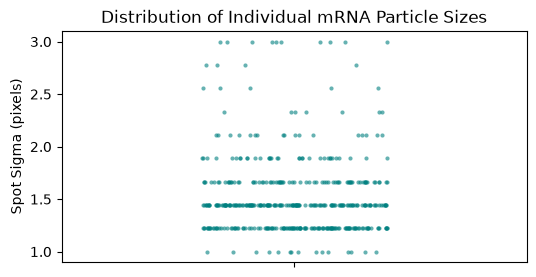

In [25]:
fh, ax = plt.subplots(1, 1, figsize=(6, 3))
sns.stripplot(data=spots_df, y="sigma", color="teal", size=3, alpha=0.6, jitter=0.2, ax=ax)
plt.title("Distribution of Individual mRNA Particle Sizes")
plt.ylabel("Spot Sigma (pixels)")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_size_distr.png")
plt.show()
# Tight, dark band of the overlapping dots tells us that the found mRNA particles are the same physical size
# sign that the detectin of the single-molecule mRNAs are true

# The dots above the bands (outliers) are the abnormally large spots that are often either active transcription sites
# or overlapping transcripts

# The darkest areas (where many dots overlap)= mode (most common value)

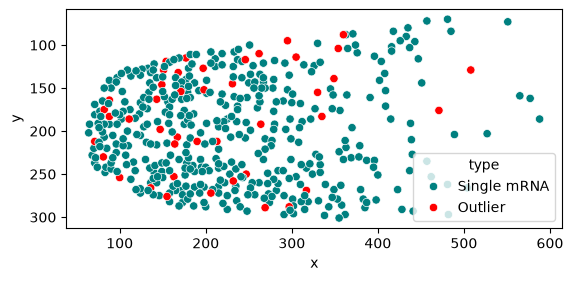

In [26]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
sns.scatterplot(data=spots_df, x="x", y="y", hue="type", palette={"Single mRNA": "teal", "Outlier": "red"})
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/true_vs_outlier_mrna.png")
plt.show()

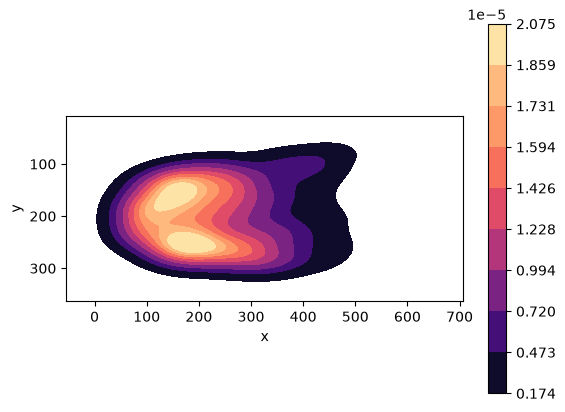

In [40]:
sns.kdeplot(data=spots_df, x="x", y="y", fill=True, cmap="magma", cbar=True)
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.savefig(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_kde.png")
plt.show()
# Brightest/Hottest color (yellow)= mRNA hotspots where they're packed close together
# Medium colors (purple/red)= steady spread of individual cytoplasmic mRNA
# Darkest= very few or zero mRNA particles

In [41]:
counts_table = spots_df["type"].value_counts().reset_index()
counts_table.columns = ["Spot Type", "Count"]
print(counts_table)
counts_table

     Spot Type  Count
0  Single mRNA    404
1      Outlier     43


In [42]:
summary_table = spots_df.groupby("type", as_index=False).agg(Total_Spots=("sigma", "count"), Mean_Sigma=("sigma", "mean"), Min_Sigma=("sigma", "min"), Max_Sigma=("sigma", "max"))
summary_table = summary_table.round(2)
print(summary_table)

          type  Total_Spots  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier           43        2.47       2.11       3.00
1  Single mRNA          404        1.43       1.00       1.89


In [43]:
print(spots_df.head(10))

       y      x     sigma         type
0  191.0  201.0  1.444444  Single mRNA
1  264.0  215.0  1.888889  Single mRNA
2  256.0  113.0  1.666667  Single mRNA
3  132.0  168.0  2.111111      Outlier
4  248.0  140.0  1.444444  Single mRNA
5  236.0  116.0  1.888889  Single mRNA
6  208.0  246.0  1.666667  Single mRNA
7  288.0  200.0  1.888889  Single mRNA
8  124.0  326.0  1.666667  Single mRNA
9  141.0  201.0  1.666667  Single mRNA


In [44]:
spots_df.to_csv(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_spots_full.csv", index=False)
summary_table.to_csv(r"/Users/avaireemcconnell/Documents/GitHub/ABIO588/mrna_summary.csv", index=False)

In [91]:
import glob
batch_mrna_dir = 'Batch'
filepaths = glob.glob(os.path.join(batch_mrna_dir, '*.tif'))
print(len(filepaths))

2


In [92]:
from skimage import feature

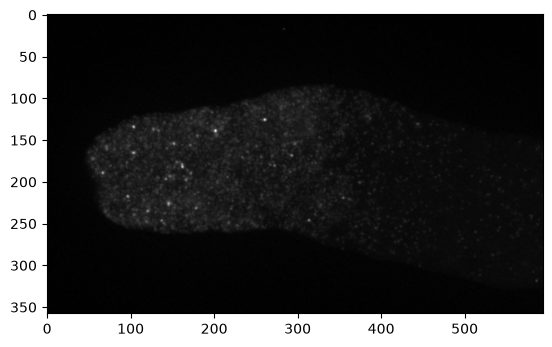

<class 'numpy.ndarray'>
['Batch/Img04_mRNA.tif', 'Batch/Img02_mRNA.tif']


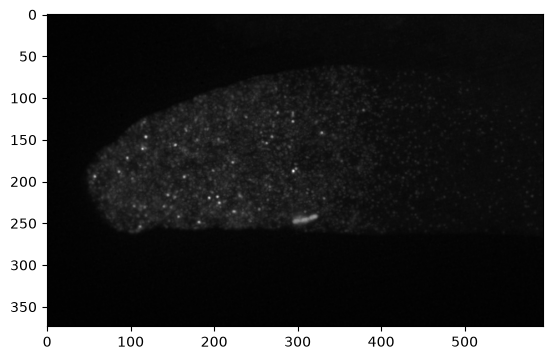

<class 'numpy.ndarray'>
['Batch/Img04_mRNA.tif', 'Batch/Img02_mRNA.tif']
                  Image  Single_mRNA
0  Batch/Img04_mRNA.tif         1629
1  Batch/Img02_mRNA.tif         1930


In [93]:
counts = []
for file in filepaths:
    img = tifffile.imread(file)
    plt.imshow(img, cmap="gray")
    plt.show()
    print(type(img))
    print(filepaths)

    img_norm = (img - img.min()) / (img.max() - img.min())

    spots = feature.blob_log(img_norm, min_sigma=1, max_sigma=4, num_sigma=10, threshold=0.01, overlap=0.1)
    if len(spots) > 0:
        single_count = int((spots[:, 2] <= 2.0).sum())
    else:
        single_count = 0

    counts.append({"Image": str(file), "Single_mRNA": single_count})

counts_table = pd.DataFrame(counts)
print(counts_table)

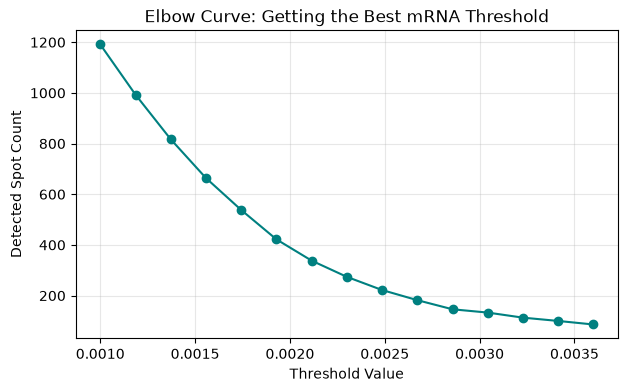

In [94]:
img = tifffile.imread(filepaths[0])
img_float = img_as_float(img)

thresholds = np.linspace(0.001, 0.0036, 15)
spot_counts = []
for t in thresholds:
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=t, overlap=0.0)
    spot_counts.append(len(spots))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, spot_counts, marker="o", color="teal")
plt.xlabel("Threshold Value")
plt.ylabel("Detected Spot Count")
plt.title("Elbow Curve: Getting the Best mRNA Threshold")
plt.grid(True, alpha=0.3)
plt.show()

In [95]:
drops = -np.diff(spot_counts)
elbow_index = np.argmax(np.diff(drops)) + 1
best_thresh = thresholds[elbow_index]
print(f"Suggested Elbow Threshold: {best_thresh:.4f}")
print(f"Spots detected at this threshold: {spot_counts[elbow_index]}")

Suggested Elbow Threshold: 0.0030
Spots detected at this threshold: 133


In [96]:
counts = []
for file in filepaths:
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    counts.append({"Image": os.path.basename(file), "Total_Unique_Particles": len(spots)})

    counts_table = pd.DataFrame(counts)
    print(counts_table)

            Image  Total_Unique_Particles
0  Img04_mRNA.tif                     396
            Image  Total_Unique_Particles
0  Img04_mRNA.tif                     396
1  Img02_mRNA.tif                     404


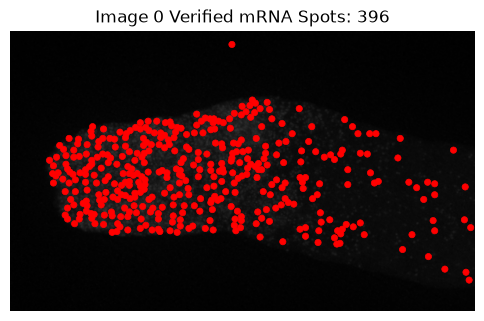

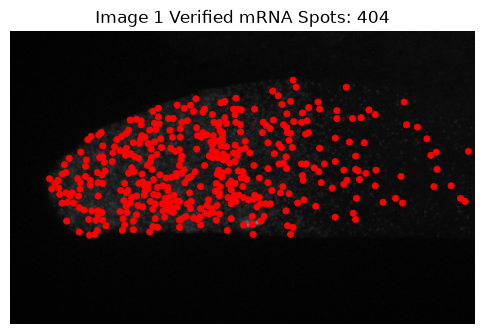

In [97]:
for i, file in enumerate (filepaths):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    fh, ax = plt.subplots(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    for spot in spots:
        y, x, r = spot
        circle = plt.Circle((x, y), radius=4, color="red", linewidth=0.5, fill=True)
        ax.add_patch(circle)

    ax.set_title(f"Image {i} Verified mRNA Spots: {len(spots)}")
    ax.axis("off")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/verified_mrna.png")
    plt.close(fig)

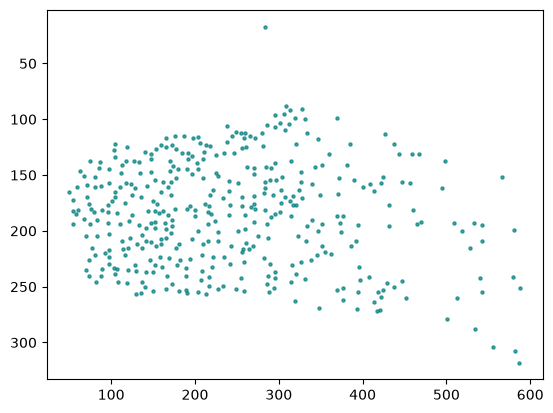

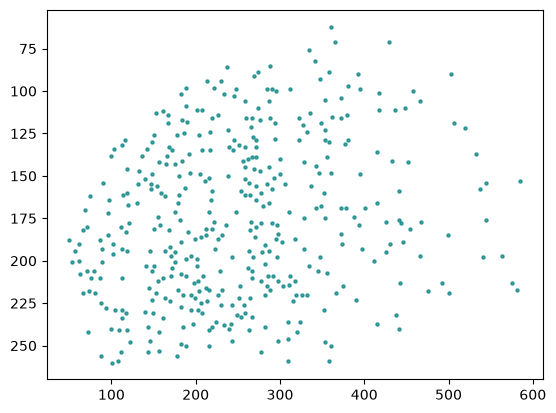

In [98]:
for i, file in enumerate (filepaths):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    y = spots[:, 1]
    x = spots[:, 0]
    plt.scatter(y, x, s=20, alpha=0.7, c="teal", marker=".")
    plt.gca().invert_yaxis()
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/figure_{i}.png")
    plt.show()
    plt.close()

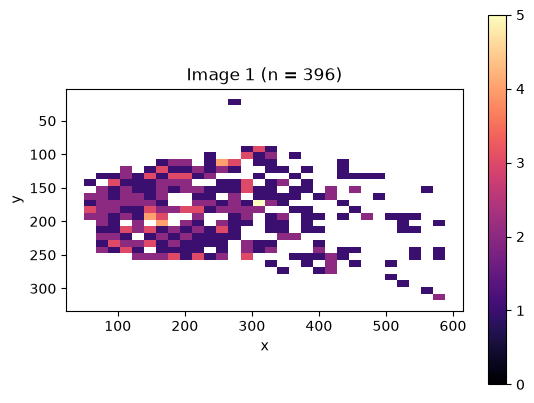

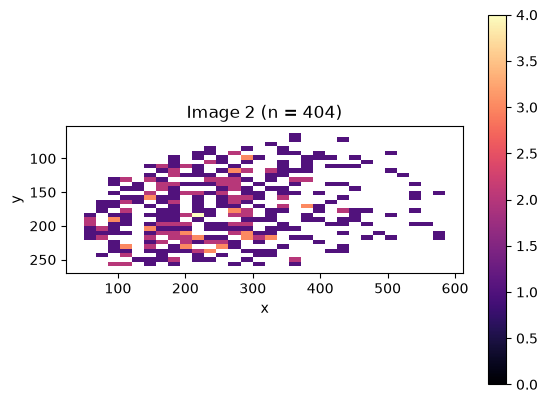

In [105]:
all_spots = []
for i, file in enumerate(filepaths[:2]):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots.append(df)

    sns.histplot(data=df, x="x", y="y", bins=30, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/histplot_{i}.png")
    plt.show()
    plt.close()

In [106]:
spots_df = pd.concat(all_spots, ignore_index=True)
print(spots_df.head())
print(spots_df["Image"].value_counts())
print(spots_df.tail())

       y      x     sigma    Image
0  139.0  202.0  1.222222  Image 1
1  125.0  261.0  1.222222  Image 1
2  134.0  104.0  1.222222  Image 1
3  182.0  162.0  1.222222  Image 1
4  165.0  104.0  1.222222  Image 1
Image
Image 2    404
Image 1    396
Name: count, dtype: int64
         y      x     sigma    Image
795  167.0  120.0  1.000000  Image 2
796   89.0  358.0  1.000000  Image 2
797  119.0  167.0  1.222222  Image 2
798  125.0  186.0  1.222222  Image 2
799  239.0  282.0  2.333333  Image 2


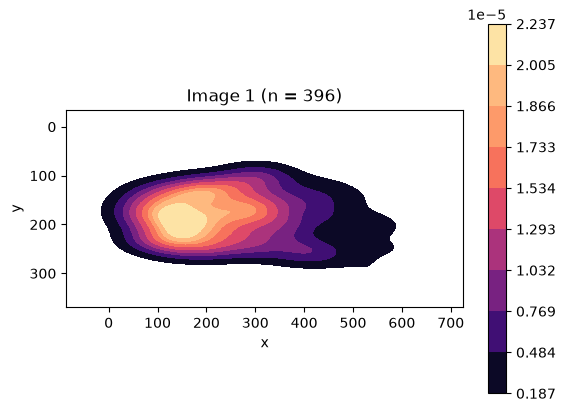

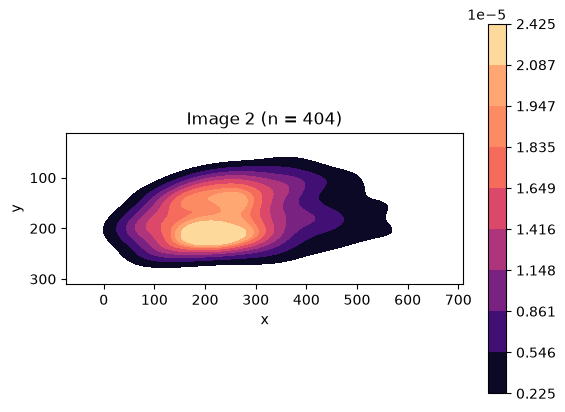

In [107]:
all_spots = []
for i, file in enumerate(filepaths[:2]):
    img = tifffile.imread(file)
    img_float = img_as_float(img)
    spots = blob_log(img_float, min_sigma=1, max_sigma=3, threshold=0.002, overlap=0.0)

    df = pd.DataFrame(spots, columns=["y", "x", "sigma"])
    df["Image"] = f"Image {i + 1}"
    all_spots.append(df)

    sns.kdeplot(data=df, x="x", y="y", fill=True, cmap="magma", cbar=True)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal")
    plt.title(f"Image {i +1} (n = {len(df)})")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/kde_heatmap_{i}.png")
    plt.show()
    plt.close()

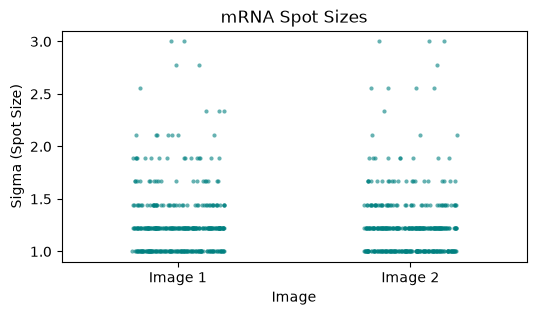

In [109]:
fh, ax = plt.subplots(1, 1, figsize=(6, 3))
sns.stripplot(data=spots_df, x="Image", y="sigma", color="teal", size=3, jitter=0.2, alpha=0.6, ax=ax)
plt.ylabel("Sigma (Spot Size)")
plt.title("mRNA Spot Sizes")
plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/stripplot.png")
plt.show()

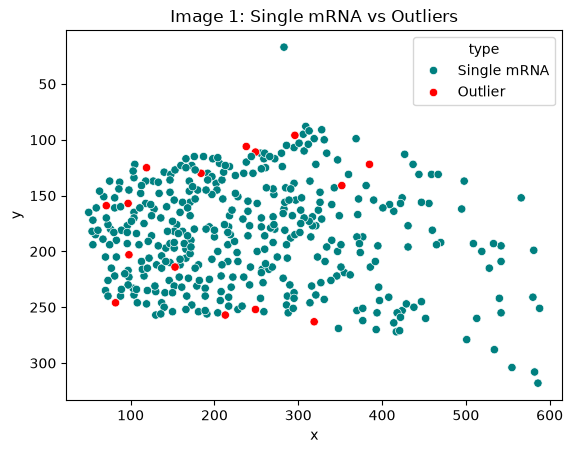

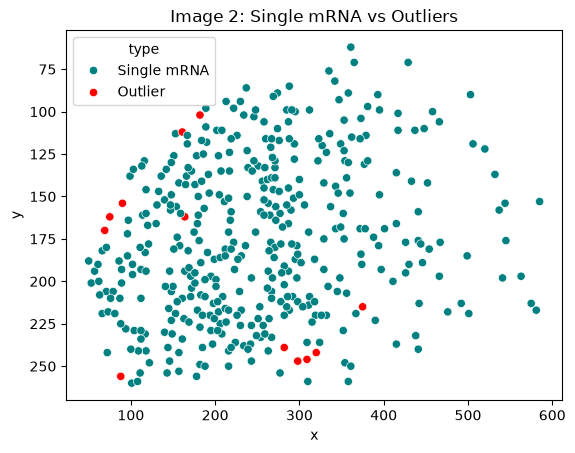

In [112]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    sns.scatterplot(data=sub_df, x="x", y="y", hue="type", palette={"Single mRNA": "teal", "Outlier": "red"})
    plt.gca().invert_yaxis()
    plt.title(f"{img_name}: Single mRNA vs Outliers")
    plt.savefig(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/mrna_vs_outlier_scatter_{i}.png")
    plt.show()
    plt.close()

In [114]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    counts_table = sub_df["type"].value_counts().reset_index()
    counts_table.columns = ["Type", "Count"]
    counts_table.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/mrna_vs_outlier_scatter_{i}.csv", index=False)
    print(counts_table)

          Type  Count
0  Single mRNA    381
1      Outlier     15
          Type  Count
0  Single mRNA    392
1      Outlier     12


In [116]:
spots_df["type"] = np.where(spots_df["sigma"] > 2.0, "Outlier", "Single mRNA")
for i, img_name in enumerate(spots_df["Image"].unique()):
    sub_df = spots_df[spots_df["Image"] == img_name]
    sub_summary = sub_df.groupby("type", as_index=False).agg(Count=("sigma", "count"), Mean_Sigma=("sigma", "mean"), Min_Sigma=("sigma", "min"), Max_Sigma=("sigma", "max"))
    sub_summary = sub_summary.round(2)
    print(f"{img_name} Summary")
    print(sub_summary)
    sub_summary.to_csv(rf"/Users/avaireemcconnell/Documents/GitHub/ABIO588/Batch/sub_summary_{i}.csv", index=False)

Image 1 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     15        2.39       2.11       3.00
1  Single mRNA    381        1.22       1.00       1.89
Image 2 Summary
          type  Count  Mean_Sigma  Min_Sigma  Max_Sigma
0      Outlier     12        2.56       2.11       3.00
1  Single mRNA    392        1.20       1.00       1.89
